## TCGA-KIRC: data acquisition and initial quality control

Purpose: This notebook will execute the first stage(01) of the project:
1. Obtain and inspect TCGA-KIRC clinical and gene-expression data.
2. Perform initial data-quality checks before data cleaning.

**Dataset:** TCGA Kidney Renal Clear Cell Carcinoma (TCGA-KIRC)  
**Primary outcome:** Overall survival

In [26]:
#01-c1
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lifelines

PROJECT_DIR = Path.cwd().parent

# Defining paths once so the rest of the notebook is readable and reproducible.
DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

print(f"Python version:     {sys.version.split()[0]}")
print(f"pandas version:     {pd.__version__}")
print(f"numpy version:      {np.__version__}")
print(f"seaborn version:    {sns.__version__}")
print(f"lifelines version:  {lifelines.__version__}")
print(f"\nProject directory:  {PROJECT_DIR}")

for folder in [RAW_DATA_DIR, PROCESSED_DATA_DIR, RESULTS_DIR]:
    print(f"{'✓' if folder.exists() else '✗'} {folder}")

Python version:     3.11.17
pandas version:     2.3.3
numpy version:      2.4.6
seaborn version:    0.13.2
lifelines version:  0.30.3

Project directory:  /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis
✓ /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis/data/raw
✓ /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis/data/processed
✓ /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis/results


## Data sources

For the primary TCGA-KIRC analysis, this notebook will use three public, precompiled files from the UCSC Xena GDC hub:

1. RNA-seq gene expression: HTSeq-FPKM values.
2. Clinical phenotype data: demographic and pathological variables.
3. Survival data: overall-survival time and event status.

The raw downloaded files will be saved in `data/raw/`.

In [27]:
#01-c2
DATA_SOURCES = {
    "expression": {
        "description": "TCGA-KIRC RNA-seq gene expression (HTSeq-FPKM)",
        "url": "https://gdc.xenahubs.net/download/TCGA-KIRC.htseq_fpkm.tsv.gz",
        "local_filename": "TCGA-KIRC.htseq_fpkm.tsv.gz",
    },
    "phenotype": {
        "description": "TCGA-KIRC clinical phenotype data",
        "url": "https://gdc.xenahubs.net/download/TCGA-KIRC.GDC_phenotype.tsv.gz",
        "local_filename": "TCGA-KIRC.GDC_phenotype.tsv.gz",
    },
    "survival": {
        "description": "TCGA-KIRC survival data",
        "url": "https://gdc.xenahubs.net/download/TCGA-KIRC.survival.tsv.gz",
        "local_filename": "TCGA-KIRC.survival.tsv.gz",
    },
}

source_manifest = pd.DataFrame(DATA_SOURCES).T
source_manifest

,description,url,local_filename
expression,TCGA-KIRC RNA-seq gene expression (HTSeq-FPKM),https://gdc.xenahubs.net/download/TCGA-KIRC.ht...,TCGA-KIRC.htseq_fpkm.tsv.gz
phenotype,TCGA-KIRC clinical phenotype data,https://gdc.xenahubs.net/download/TCGA-KIRC.GD...,TCGA-KIRC.GDC_phenotype.tsv.gz
survival,TCGA-KIRC survival data,https://gdc.xenahubs.net/download/TCGA-KIRC.su...,TCGA-KIRC.survival.tsv.gz


### Download raw clinical data

**Purpose:** Downloading TCGA-KIRC clinical information from the official GDC API.

**Output:** raw JSON file:
`data/raw/TCGA-KIRC_clinical_GDC_API.json`

In [30]:
#01-c3 — Raw clinical data downloaded


import json
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

# project raw data path defined
PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# GDC API endpoint:
gdc_cases_url = "https://api.gdc.cancer.gov/cases"

# Clinical fields required for this project
clinical_fields = [
    "submitter_id",
    "demographic.sex_at_birth",
    "demographic.vital_status",
    "demographic.age_at_index",
    "demographic.days_to_death",
    "diagnoses.days_to_last_follow_up",
    "diagnoses.ajcc_pathologic_stage",
    "diagnoses.tumor_grade",
    "diagnoses.primary_diagnosis",
    "diagnoses.classification_of_tumor",
    "follow_ups.days_to_follow_up",
]


tcga_kirc_filter = {
    "op": "in",
    "content": {
        "field": "project.project_id",
        "value": ["TCGA-KIRC"],
    },
}

query = urlencode(
    {
        "filters": json.dumps(tcga_kirc_filter),
        "fields": ",".join(clinical_fields),
        "format": "JSON",
        "size": 1000,
    }
)

with urlopen(f"{gdc_cases_url}?{query}", timeout=60) as response:
    clinical_api_data = json.load(response)

# Clinical JSON file saved
clinical_json_file = RAW_DATA_DIR / "TCGA-KIRC_clinical_GDC_API.json"

with open(clinical_json_file, "w") as file:
    json.dump(clinical_api_data, file, indent=2)

number_of_cases = clinical_api_data["data"]["pagination"]["total"]

print(f"Downloaded clinical records for {number_of_cases} TCGA-KIRC cases.")
print(f"Raw file saved as: {clinical_json_file.name}")

Downloaded clinical records for 537 TCGA-KIRC cases.
Raw file saved as: TCGA-KIRC_clinical_GDC_API.json


### Inspecting the structure of the raw clinical data

**Purpose:** Confirming the number of cases and learning how the downloaded JSON is organised.

**Input:** `data/raw/TCGA-KIRC_clinical_GDC_API.json`

In [31]:
# 01-c4
import json
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
clinical_json_file = RAW_DATA_DIR / "TCGA-KIRC_clinical_GDC_API.json"

# Load the saved raw API response.
with open(clinical_json_file, "r") as file:
    clinical_api_data = json.load(file)

clinical_cases = clinical_api_data["data"]["hits"]
first_case = clinical_cases[0]

print("Number of downloaded cases:", len(clinical_cases))
print("\nTop-level fields in one case:")
print(list(first_case.keys()))

print("\nExample patient identifier:")
print(first_case["submitter_id"])

print("\nExample demographic information:")
print(first_case["demographic"])

print("\nNumber of diagnosis records for this patient:")
print(len(first_case["diagnoses"]))

# Identifying every nested field across all cases.
demographic_fields_found = sorted(
    {
        field_name
        for case in clinical_cases
        for field_name in case.get("demographic", {}).keys()
    }
)

diagnosis_fields_found = sorted(
    {
        field_name
        for case in clinical_cases
        for diagnosis in case.get("diagnoses", [])
        for field_name in diagnosis.keys()
    }
)

print("\nDemographic fields found across all cases:")
print(demographic_fields_found)

print("\nDiagnosis fields found across all cases:")
print(diagnosis_fields_found)

Number of downloaded cases: 537

Top-level fields in one case:
['id', 'follow_ups', 'submitter_id', 'diagnoses', 'demographic']

Example patient identifier:
TCGA-B0-5098

Example demographic information:
{'vital_status': 'Dead', 'age_at_index': 53, 'days_to_death': 1584, 'sex_at_birth': 'female'}

Number of diagnosis records for this patient:
1

Demographic fields found across all cases:
['age_at_index', 'days_to_death', 'sex_at_birth', 'vital_status']

Diagnosis fields found across all cases:
['ajcc_pathologic_stage', 'classification_of_tumor', 'days_to_last_follow_up', 'primary_diagnosis', 'tumor_grade']


### Checking nested clinical-record counts

**Purpose:** Counting diagnosis and follow-up records per patient before converting the
raw JSON into one row per patient.


In [7]:
# 01-c5

import json
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
clinical_json_file = RAW_DATA_DIR / "TCGA-KIRC_clinical_GDC_API.json"

with open(clinical_json_file, "r") as file:
    clinical_api_data = json.load(file)

clinical_cases = clinical_api_data["data"]["hits"]

nested_record_counts = pd.DataFrame(
    {
        "patient_id": [case["submitter_id"] for case in clinical_cases],
        "number_of_diagnoses": [
            len(case.get("diagnoses", []))
            for case in clinical_cases
        ],
        "number_of_follow_ups": [
            len(case.get("follow_ups", []))
            for case in clinical_cases
        ],
    }
)

print("Diagnosis records per patient:")
print(nested_record_counts["number_of_diagnoses"].value_counts().sort_index())

print("\nFollow-up records per patient:")
print(nested_record_counts["number_of_follow_ups"].value_counts().sort_index())

print("\nSummary:")
display(nested_record_counts.describe())

Diagnosis records per patient:
number_of_diagnoses
1    338
2    145
3     34
4     17
5      2
6      1
Name: count, dtype: int64

Follow-up records per patient:
number_of_follow_ups
2     197
3     122
4     121
5      60
6      24
7       6
8       6
10      1
Name: count, dtype: int64

Summary:


,number_of_diagnoses,number_of_follow_ups
count,537.000000,537.000000
mean,1.515829,3.329609
std,0.805896,1.373156
min,1.000000,2.000000
25%,1.000000,2.000000
50%,1.000000,3.000000
75%,2.000000,4.000000
max,6.000000,10.000000


### 7 — Inspecting multiple diagnosis records

**Purpose:** Examining diagnosis records for patients with more than one record.

In [32]:
# c1-06: Inspects multiple diagnosis records (creates a long table), one row per diagnosis record.

import json
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
clinical_json_file = RAW_DATA_DIR / "TCGA-KIRC_clinical_GDC_API.json"

with open(clinical_json_file, "r") as file:
    clinical_api_data = json.load(file)

clinical_cases = clinical_api_data["data"]["hits"]

diagnosis_rows = []

for case in clinical_cases:
    patient_id = case["submitter_id"]

    for diagnosis_number, diagnosis in enumerate(case.get("diagnoses", []), start=1):
        diagnosis_rows.append(
            {
                "patient_id": patient_id,
                "diagnosis_number": diagnosis_number,
                "primary_diagnosis": diagnosis.get("primary_diagnosis"),
                "tumor_stage": diagnosis.get("ajcc_pathologic_stage"),
                "tumor_grade": diagnosis.get("tumor_grade"),
                "tumor_classification": diagnosis.get("classification_of_tumor"),
                "days_to_last_follow_up": diagnosis.get("days_to_last_follow_up"),
            }
        )

diagnoses_long = pd.DataFrame(diagnosis_rows)

number_of_records_per_patient = diagnoses_long["patient_id"].value_counts()
patients_with_multiple_diagnoses = number_of_records_per_patient[
    number_of_records_per_patient > 1
]

print("Total diagnosis records:", len(diagnoses_long))
print("Patients with multiple diagnosis records:", len(patients_with_multiple_diagnoses))

example_patient_ids = patients_with_multiple_diagnoses.index[:5]

print("\nFive example patients with multiple diagnosis records:")
display(
    diagnoses_long[
        diagnoses_long["patient_id"].isin(example_patient_ids)
    ].sort_values(["patient_id", "diagnosis_number"])
)

Total diagnosis records: 814
Patients with multiple diagnosis records: 199

Five example patients with multiple diagnosis records:


,patient_id,diagnosis_number,primary_diagnosis,tumor_stage,tumor_grade,tumor_classification,days_to_last_follow_up
717,TCGA-BP-4343,1,Not Reported,None,None,not reported,NaN
718,TCGA-BP-4343,2,"Clear cell adenocarcinoma, NOS",Stage III,G3,primary,NaN
719,TCGA-BP-4343,3,Not Reported,None,None,not reported,NaN
720,TCGA-BP-4343,4,Not Reported,None,None,not reported,NaN
721,TCGA-BP-4343,5,Not Reported,None,None,not reported,NaN
408,TCGA-BP-4760,1,"Clear cell adenocarcinoma, NOS",Stage I,G2,primary,NaN
409,TCGA-BP-4760,2,Clear cell carcinoma,None,None,Synchronous primary,NaN
410,TCGA-BP-4760,3,"Adenocarcinoma, NOS",None,None,Prior primary,NaN
411,TCGA-BP-4760,4,Not Reported,None,None,not reported,NaN
446,TCGA-BP-5178,1,"Clear cell adenocarcinoma, NOS",None,None,metastasis,NaN


### Validate the primary-diagnosis selection rule

**Purpose:** the Prior table(displayed above) shows that some extra diagnosis records are metastases, recurrences, prior cancers, synchronous cancers, or “not reported”. So it is necessary to test whether selecting the record labelled `primary` produces exactly one diagnosis record per patient. As follows : For each patient, select the diagnosis record where tumor_classification is primary


In [33]:
# 01-c7 — Validates the primary-diagnosis selection rule

# Count every tumour-classification label
print("Tumour-classification labels:")
print(
    diagnoses_long["tumor_classification"]
    .fillna("missing")
    .value_counts()
)

# Identify records explicitly labelled as the primary tumour
is_primary_diagnosis = (
    diagnoses_long["tumor_classification"]
    .fillna("")
    .str.lower()
    .eq("primary")
)

primary_diagnosis_counts = (
    diagnoses_long.loc[is_primary_diagnosis, "patient_id"]
    .value_counts()
)

number_with_one_primary = (primary_diagnosis_counts == 1).sum()
number_with_multiple_primary = (primary_diagnosis_counts > 1).sum()
number_with_no_primary = (
    diagnoses_long["patient_id"].nunique() - len(primary_diagnosis_counts)
)

print("\nPrimary-diagnosis rule check:")
print(f"Patients with exactly one primary diagnosis: {number_with_one_primary}")
print(f"Patients with multiple primary diagnoses:   {number_with_multiple_primary}")
print(f"Patients with no primary diagnosis:         {number_with_no_primary}")

Tumour-classification labels:
tumor_classification
primary                537
not reported           121
Prior primary           76
metastasis              37
Synchronous primary     30
recurrence              13
Name: count, dtype: int64

Primary-diagnosis rule check:
Patients with exactly one primary diagnosis: 537
Patients with multiple primary diagnoses:   0
Patients with no primary diagnosis:         0


Result : The rule is validated(from results above):
- Every one of the 537 patients has exactly one record labelled primary.
- No patient has multiple primary records.
- No patient is missing a primary record.
Project can now create a one-row-per-patient clinical table.
Please note that no patients have been filtered out; only selection of their verified primary diagnosis record is made.

### Create a one-row-per-patient clinical table

**Purpose:** Combining demographic information with each patient’s verified primary
diagnosis record.

**Selection rule:** Keeping the one diagnosis record labelled `primary` per patient.

**Output:** An patient-level clinical table.

In [34]:
# 01-c8  Creates a one-row-per-patient clinical table

# Keeps only the verified primary diagnosis for each patient.
primary_diagnoses = diagnoses_long.loc[is_primary_diagnosis].copy()

primary_diagnoses = primary_diagnoses[
    [
        "patient_id",
        "primary_diagnosis",
        "tumor_stage",
        "tumor_grade",
        "days_to_last_follow_up",
    ]
]

# Creates a one-row-per-patient demographic table.
demographic_rows = []

for case in clinical_cases:
    demographic = case.get("demographic", {})

    demographic_rows.append(
        {
            "patient_id": case["submitter_id"],
            "sex_at_birth": demographic.get("sex_at_birth"),
            "vital_status": demographic.get("vital_status"),
            "age_at_index": demographic.get("age_at_index"),
            "days_to_death": demographic.get("days_to_death"),
        }
    )

demographics_table = pd.DataFrame(demographic_rows)

# Merges demographic and primary-diagnosis information.
patient_clinical_table = demographics_table.merge(
    primary_diagnoses,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

# Confirms there is exactly one row per patient.
print("Rows in patient-level table:", len(patient_clinical_table))
print("Unique patient IDs:", patient_clinical_table["patient_id"].nunique())

display(patient_clinical_table.head())

Rows in patient-level table: 537
Unique patient IDs: 537


,patient_id,sex_at_birth,vital_status,age_at_index,days_to_death,primary_diagnosis,tumor_stage,tumor_grade,days_to_last_follow_up
0,TCGA-B0-5098,female,Dead,53,1584.0,"Clear cell adenocarcinoma, NOS",Stage I,G3,NaN
1,TCGA-BP-4165,female,Alive,64,NaN,"Clear cell adenocarcinoma, NOS",Stage I,G1,NaN
2,TCGA-BP-4166,male,Alive,69,NaN,"Clear cell adenocarcinoma, NOS",Stage III,G3,13.0
3,TCGA-B0-4810,male,Dead,47,478.0,"Clear cell adenocarcinoma, NOS",Stage III,G3,NaN
4,TCGA-DV-5568,male,Alive,26,NaN,"Clear cell adenocarcinoma, NOS",Stage I,G2,NaN


### Inspecting follow-up records

**Purpose:** Examine follow-up records before calculating overall-survival time.

In [36]:
# 01-c9 Inspects follow-up records
import json
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
clinical_json_file = RAW_DATA_DIR / "TCGA-KIRC_clinical_GDC_API.json"

with open(clinical_json_file, "r") as file:
    clinical_api_data = json.load(file)

clinical_cases = clinical_api_data["data"]["hits"]

follow_up_rows = []

for case in clinical_cases:
    patient_id = case["submitter_id"]

    for follow_up_number, follow_up in enumerate(case.get("follow_ups", []), start=1):
        follow_up_rows.append(
            {
                "patient_id": patient_id,
                "follow_up_number": follow_up_number,
                "days_to_follow_up": follow_up.get("days_to_follow_up"),
            }
        )

follow_ups_long = pd.DataFrame(follow_up_rows)

print("Total follow-up records:", len(follow_ups_long))
print("Patients with follow-up records:", follow_ups_long["patient_id"].nunique())

print("\nMissing values in follow-up time:")
print(follow_ups_long["days_to_follow_up"].isna().sum())

print("\nExample follow-up records:")
display(follow_ups_long.head(10))

Total follow-up records: 1788
Patients with follow-up records: 537

Missing values in follow-up time:
274

Example follow-up records:


,patient_id,follow_up_number,days_to_follow_up
0,TCGA-B0-5098,1,1584.0
1,TCGA-B0-5098,2,1584.0
2,TCGA-BP-4165,1,1838.0
3,TCGA-BP-4165,2,3037.0
4,TCGA-BP-4165,3,2946.0
5,TCGA-BP-4165,4,3037.0
6,TCGA-BP-4165,5,1049.0
7,TCGA-BP-4166,1,13.0
8,TCGA-BP-4166,2,13.0
9,TCGA-B0-4810,1,205.0


Two important things have been found:
- Every patient has at least one follow-up record.
- Some follow-up entries are missing or repeated, so I will use the maximum valid follow-up day per patient as the final censoring time for patients who are alive. Before calculating survival time, it is better to check if vital_status and days_to_death agree

### Validate inputs for overall-survival time

**Purpose:** Check vital-status categories and confirm that patients recorded as dead
have a recorded time to death.

In [37]:
# 01-c10 Validates inputs for overall-survival time

print("Vital-status categories:")
print(patient_clinical_table["vital_status"].value_counts(dropna=False))

patients_recorded_as_dead = patient_clinical_table[
    patient_clinical_table["vital_status"] == "Dead"
]

patients_recorded_as_alive = patient_clinical_table[
    patient_clinical_table["vital_status"] == "Alive"
]

print("\nPatients recorded as dead:", len(patients_recorded_as_dead))
print(
    "Dead patients missing days_to_death:",
    patients_recorded_as_dead["days_to_death"].isna().sum(),
)

print("\nPatients recorded as alive:", len(patients_recorded_as_alive))

# Uses the largest valid follow-up day for each patient.
maximum_follow_up = (
    follow_ups_long.groupby("patient_id", as_index=False)["days_to_follow_up"]
    .max()
    .rename(columns={"days_to_follow_up": "maximum_days_to_follow_up"})
)

print(
    "\nPatients missing all follow-up times:",
    maximum_follow_up["maximum_days_to_follow_up"].isna().sum(),
)

Vital-status categories:
vital_status
Alive    360
Dead     177
Name: count, dtype: int64

Patients recorded as dead: 177
Dead patients missing days_to_death: 0

Patients recorded as alive: 360

Patients missing all follow-up times: 0


Survival Inputs : 177 patients have a recorded death event, and all 177 have a valid time to death.
360 patients are alive, and all have at least one valid follow-up time.
Therefore, let me calculate overall-survival time for all 537 patients

### Create overall-survival outcome variables

**Purpose:** Create time-to-event variables: survival analysis.

**Definitions:**

- `event_observed = 1` means death occurred.
- `event_observed = 0` means the patient was alive at last follow-up.
- `overall_survival_days` is time to death for deaths and time to last follow-up
  for patients who were alive.

In [38]:
# 01-c11 Creates overall-survival outcome variables

import numpy as np

# Adds each patient's final available follow-up time.
survival_table = patient_clinical_table.merge(
    maximum_follow_up,
    on="patient_id",
    how="left",
    validate="one_to_one",
)

# event of interest: Death.
survival_table["event_observed"] = (
    survival_table["vital_status"] == "Dead"
).astype(int)

# Uses time to death for deaths; otherwise use the final follow-up time.
survival_table["overall_survival_days"] = np.where(
    survival_table["event_observed"] == 1,
    survival_table["days_to_death"],
    survival_table["maximum_days_to_follow_up"],
)

survival_table["overall_survival_years"] = (
    survival_table["overall_survival_days"] / 365.25
)

print("Rows in survival table:", len(survival_table))
print("Deaths (event_observed = 1):", survival_table["event_observed"].sum())
print("Alive/censored (event_observed = 0):", (survival_table["event_observed"] == 0).sum())
print(
    "Missing overall-survival times:",
    survival_table["overall_survival_days"].isna().sum(),
)

display(
    survival_table[
        [
            "patient_id",
            "vital_status",
            "event_observed",
            "overall_survival_days",
            "overall_survival_years",
        ]
    ].head()
)

Rows in survival table: 537
Deaths (event_observed = 1): 177
Alive/censored (event_observed = 0): 360
Missing overall-survival times: 0


,patient_id,vital_status,event_observed,overall_survival_days,overall_survival_years
0,TCGA-B0-5098,Dead,1,1584.0,4.336756
1,TCGA-BP-4165,Alive,0,3037.0,8.314853
2,TCGA-BP-4166,Alive,0,13.0,0.035592
3,TCGA-B0-4810,Dead,1,478.0,1.308693
4,TCGA-DV-5568,Alive,0,370.0,1.013005


### Quality control for derived survival outcomes

**Purpose:** Checking that the calculated survival times are positive and summarizing
survival time separately for deaths and censored patients.

In [40]:
# 01-c12 Quality control for derived survival outcomes

number_of_nonpositive_times = (
    survival_table["overall_survival_days"] <= 0
).sum()

print("Patients with zero or negative survival time:", number_of_nonpositive_times)

survival_summary = (
    survival_table
    .groupby("event_observed")["overall_survival_days"]
    .agg(["count", "min", "median", "mean", "max"])
    .rename(
        index={
            0: "Alive / censored",
            1: "Death observed",
        }
    )
)

print("\nSurvival-time summary in days:")
display(survival_summary)

print("\nOverall survival-time range in years:")
print(
    f"{survival_table['overall_survival_years'].min():.2f} "
    f"to {survival_table['overall_survival_years'].max():.2f} years"
)

Patients with zero or negative survival time: 4

Survival-time summary in days:


,count,min,median,mean,max
event_observed,,,,,
Alive / censored,360,0.0,1443.0,1534.847222,4537.0
Death observed,177,0.0,782.0,926.717514,3615.0



Overall survival-time range in years:
0.00 to 12.42 years


As noted from results above :Four patients have survival time of exactly zero days. Now it is needed to inspect them before deciding whether they are data-entry artifacts or legitimate same-day records. For this project, they will almost certainly be excluded later because Cox survival models require positive follow-up time.

### Inspect nonpositive survival times

**Purpose:** Examine patients with zero or negative calculated survival time before
making any exclusion decision.

In [41]:
# 01-13 Inspects nonpositive survival times

nonpositive_survival_records = survival_table[
    survival_table["overall_survival_days"] <= 0
].copy()

print("Number of records with zero or negative survival time:")
print(len(nonpositive_survival_records))

display(
    nonpositive_survival_records[
        [
            "patient_id",
            "sex_at_birth",
            "age_at_index",
            "vital_status",
            "event_observed",
            "days_to_death",
            "maximum_days_to_follow_up",
            "overall_survival_days",
            "tumor_stage",
            "tumor_grade",
        ]
    ].sort_values("patient_id")
)

Number of records with zero or negative survival time:
4


,patient_id,sex_at_birth,age_at_index,vital_status,event_observed,days_to_death,maximum_days_to_follow_up,overall_survival_days,tumor_stage,tumor_grade
462,TCGA-A3-A8OU,female,74,Alive,0,NaN,0.0,0.0,Stage I,G1
469,TCGA-A3-A8OX,female,65,Alive,0,NaN,0.0,0.0,Stage I,G3
471,TCGA-B0-5104,female,89,Dead,1,0.0,0.0,0.0,Stage I,G2
37,TCGA-CJ-5689,male,89,Dead,1,0.0,0.0,0.0,Stage I,G4


The four records confirm the issue:
- Two alive patients have last follow-up recorded as day 0.
- Two deceased patients have death recorded as day 0.
These patients have no positive observed time interval, so they cannot contribute meaningful information to a Cox survival model. Therefore these shall be excluded records with invalid survival time.

### Exclude nonpositive survival times

**Purpose:** Create a survival-analysis candidate table containing only patients with
positive overall-survival time.

**Exclusion rule:** Exclude patients whose calculated overall-survival time is zero
or negative. The original `survival_table` remain unchanged.

In [42]:
# 01-14 Excludes nonpositive survival times

survival_analysis_candidates = survival_table[
    survival_table["overall_survival_days"] > 0
].copy()

cohort_flow = pd.DataFrame(
    {
        "step": [
            "Downloaded TCGA-KIRC cases",
            "Excluded: nonpositive survival time",
            "Remaining survival-analysis candidates",
        ],
        "number_of_patients": [
            len(survival_table),
            len(survival_table) - len(survival_analysis_candidates),
            len(survival_analysis_candidates),
        ],
    }
)

display(cohort_flow)

print(
    "Minimum retained survival time:",
    survival_analysis_candidates["overall_survival_days"].min(),
    "days",
)

,step,number_of_patients
0,Downloaded TCGA-KIRC cases,537
1,Excluded: nonpositive survival time,4
2,Remaining survival-analysis candidates,533


Minimum retained survival time: 2.0 days


### Check missing clinical variables

**Purpose:** Identify missing values in the variables required for the planned
survival-analysis model. This cell does not exclude any additional patients.

In [43]:
# 01-15 Checks missing clinical variables

required_analysis_columns = [
    "age_at_index",
    "sex_at_birth",
    "tumor_stage",
    "tumor_grade",
    "overall_survival_days",
    "event_observed",
]

missingness_summary = pd.DataFrame(
    {
        "variable": required_analysis_columns,
        "missing_count": [
            survival_analysis_candidates[column].isna().sum()
            for column in required_analysis_columns
        ],
        "missing_percent": [
            round(
                100 * survival_analysis_candidates[column].isna().mean(),
                2,
            )
            for column in required_analysis_columns
        ],
    }
)

display(missingness_summary)

,variable,missing_count,missing_percent
0,age_at_index,0,0.00
1,sex_at_birth,0,0.00
2,tumor_stage,3,0.56
3,tumor_grade,3,0.56
4,overall_survival_days,0,0.00
5,event_observed,0,0.00


Results : age, sex, survival time, and event status are complete.
Only 3 of 533 patients are missing stage, and 3 are missing grade. Before deciding whether to exclude them, we need to check:
1. Whether they are the same patients.
2. Whether any non-missing entries use labels such as “Not Reported.”

### Inspect stage and tumor grade record completeness

**Purpose:** Examine missing stage/grade records and review the available stage and
grade categories before applying any clinical-variable exclusions.

In [44]:
# 01-16 Inspects stage and grade tumor record completeness


patients_missing_stage_or_grade = survival_analysis_candidates[
    survival_analysis_candidates["tumor_stage"].isna()
    | survival_analysis_candidates["tumor_grade"].isna()
].copy()

print("Patients missing stage and/or grade:")
print(len(patients_missing_stage_or_grade))

display(
    patients_missing_stage_or_grade[
        [
            "patient_id",
            "tumor_stage",
            "tumor_grade",
            "sex_at_birth",
            "age_at_index",
            "event_observed",
            "overall_survival_days",
        ]
    ].sort_values("patient_id")
)

print("\nPathological-stage categories:")
print(
    survival_analysis_candidates["tumor_stage"]
    .fillna("missing")
    .value_counts()
    .sort_index()
)

print("\nTumor-grade categories:")
print(
    survival_analysis_candidates["tumor_grade"]
    .fillna("missing")
    .value_counts()
    .sort_index()
)

Patients missing stage and/or grade:
6


,patient_id,tumor_stage,tumor_grade,sex_at_birth,age_at_index,event_observed,overall_survival_days
438,TCGA-AS-3777,Stage I,None,male,63,0,1238.0
472,TCGA-B2-A4SR,Stage II,None,male,61,0,507.0
307,TCGA-B4-5838,None,G2,male,52,0,166.0
130,TCGA-BP-4798,None,G4,male,74,1,334.0
221,TCGA-GK-A6C7,Stage I,None,female,76,0,61.0
150,TCGA-MM-A563,None,G2,male,41,0,591.0



Pathological-stage categories:
tumor_stage
Stage I      265
Stage II      57
Stage III    125
Stage IV      83
missing        3
Name: count, dtype: int64

Tumor-grade categories:
tumor_grade
G1          13
G2         229
G3         206
G4          77
GX           5
missing      3
Name: count, dtype: int64


It is found that 11 patients whose stage or grade cannot be used as planned:
- 3 patients missing stage.
- 3 patients missing grade.
- 5 patients with grade GX, meaning grade was not assessable/unknown.
For the primary adjusted Cox model, I plan to retain only standard stage categories (Stage I–Stage IV) and standard grade categories (G1–G4). But it is better to measure the exact effect of this rule before applying it.


### Validate stage and grade eligibility rules

**Purpose:** Identify patients without usable pathological stage or tumor grade for
the primary adjusted Cox model.

**Valid stage:** Stage I, Stage II, Stage III, or Stage IV  
**Valid grade:** G1, G2, G3, or G4

**Important:** This cell identifies ineligible records only. It does not exclude them.

In [45]:
# 01-c17 Validates stage and grade eligibility rules

valid_stages = {"Stage I", "Stage II", "Stage III", "Stage IV"}
valid_grades = {"G1", "G2", "G3", "G4"}

has_valid_stage = survival_analysis_candidates["tumor_stage"].isin(valid_stages)
has_valid_grade = survival_analysis_candidates["tumor_grade"].isin(valid_grades)

patients_with_invalid_stage_or_grade = survival_analysis_candidates[
    ~has_valid_stage | ~has_valid_grade
].copy()

print("Patients with invalid or missing stage:", (~has_valid_stage).sum())
print("Patients with invalid or missing grade:", (~has_valid_grade).sum())
print(
    "Patients with invalid or missing stage and/or grade:",
    len(patients_with_invalid_stage_or_grade),
)

display(
    patients_with_invalid_stage_or_grade[
        [
            "patient_id",
            "tumor_stage",
            "tumor_grade",
            "event_observed",
            "overall_survival_days",
        ]
    ].sort_values("patient_id")
)

Patients with invalid or missing stage: 3
Patients with invalid or missing grade: 8
Patients with invalid or missing stage and/or grade: 11


,patient_id,tumor_stage,tumor_grade,event_observed,overall_survival_days
304,TCGA-AK-3427,Stage I,GX,0,3583.0
213,TCGA-AK-3433,Stage II,GX,0,3409.0
192,TCGA-AK-3443,Stage II,GX,0,1423.0
166,TCGA-AK-3465,Stage I,GX,0,369.0
438,TCGA-AS-3777,Stage I,None,0,1238.0
407,TCGA-B0-5096,Stage III,GX,1,68.0
472,TCGA-B2-A4SR,Stage II,None,0,507.0
307,TCGA-B4-5838,None,G2,0,166.0
130,TCGA-BP-4798,None,G4,1,334.0
221,TCGA-GK-A6C7,Stage I,None,0,61.0


Results : 537 downloaded cases
-> 4 nonpositive survival times
−> 11 unusable stage/grade records
=> 522 clinical survival-analysis patients

### Create and save the clinical survival-analysis dataset

**Purpose:** Create the analysis-ready clinical table for the primary Cox model.

**Inclusion criteria:**

- Positive overall-survival time
- Stage I, II, III, or IV
- Grade G1, G2, G3, or G4

**Output:** A local processed CSV file is generated.

In [46]:
# 01-18 Creates and save the clinical survival-analysis dataset

from pathlib import Path

valid_stages = {"Stage I", "Stage II", "Stage III", "Stage IV"}
valid_grades = {"G1", "G2", "G3", "G4"}

has_valid_stage = survival_analysis_candidates["tumor_stage"].isin(valid_stages)
has_valid_grade = survival_analysis_candidates["tumor_grade"].isin(valid_grades)

clinical_survival_analysis = survival_analysis_candidates[
    has_valid_stage & has_valid_grade
].copy()

# Verifyung the final cohort
assert clinical_survival_analysis["patient_id"].is_unique
assert clinical_survival_analysis["overall_survival_days"].gt(0).all()
assert clinical_survival_analysis["tumor_stage"].isin(valid_stages).all()
assert clinical_survival_analysis["tumor_grade"].isin(valid_grades).all()

# Saves the processed clinical table
PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

processed_clinical_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_survival_analysis.to_csv(processed_clinical_file, index=False)

cohort_flow = pd.DataFrame(
    {
        "step": [
            "Downloaded TCGA-KIRC cases",
            "Excluded: nonpositive survival time",
            "Excluded: missing or invalid stage/grade",
            "Final clinical survival-analysis cohort",
        ],
        "number_of_patients": [537, 4, 11, len(clinical_survival_analysis)],
    }
)

display(cohort_flow)

print(f"\nFinal analysis cohort: {len(clinical_survival_analysis)} patients")
print(f"Deaths in final cohort: {clinical_survival_analysis['event_observed'].sum()}")
print(f"Processed file saved as: {processed_clinical_file.name}")

,step,number_of_patients
0,Downloaded TCGA-KIRC cases,537
1,Excluded: nonpositive survival time,4
2,Excluded: missing or invalid stage/grade,11
3,Final clinical survival-analysis cohort,522



Final analysis cohort: 522 patients
Deaths in final cohort: 173
Processed file saved as: tcga_kirc_clinical_survival_analysis.csv


### Plot stage and grade distributions

**Purpose:** Visualize the pathological stage and tumor-grade distributions in the
final clinical survival-analysis cohort.

**Figure type:** Seaborn count plots

**Output:** A PNG figure saved in `results/figures/`.

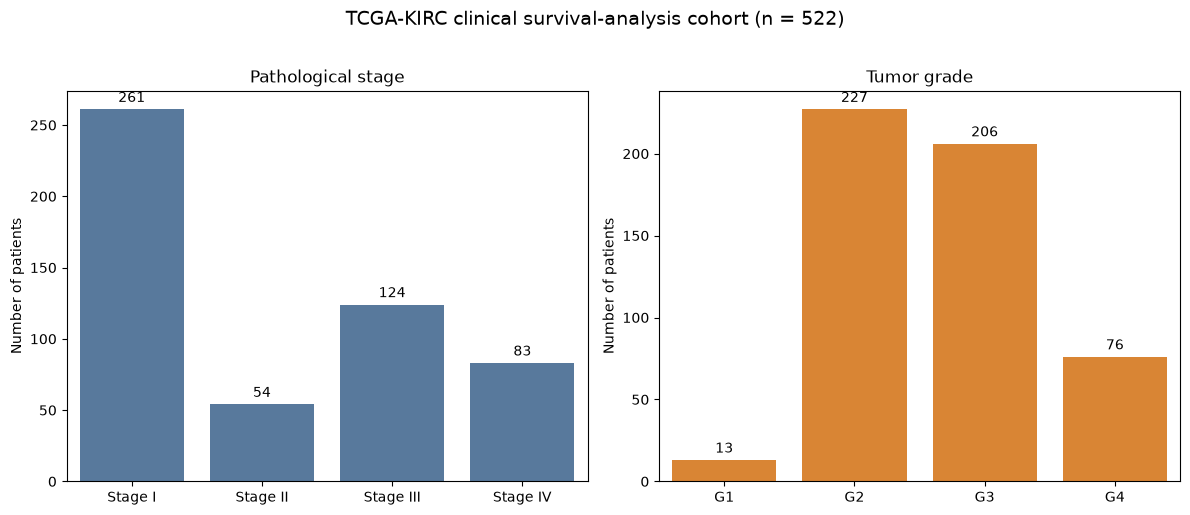

Figure saved as: figure_01_stage_and_grade_distribution.png


In [47]:
# 01-19 Plots stage and grade distributions

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the saved processed clinical dataset.
PROJECT_DIR = Path.cwd().parent
processed_clinical_file = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_survival_analysis = pd.read_csv(processed_clinical_file)

# Defines clinical ordering.
stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
grade_order = ["G1", "G2", "G3", "G4"]

# Creates two side-by-side Seaborn count plots.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

sns.countplot(
    data=clinical_survival_analysis,
    x="tumor_stage",
    order=stage_order,
    color="#4C78A8",
    ax=axes[0],
)

sns.countplot(
    data=clinical_survival_analysis,
    x="tumor_grade",
    order=grade_order,
    color="#F58518",
    ax=axes[1],
)

# Adds patient counts above every bar.
for axis in axes:
    for container in axis.containers:
        axis.bar_label(container, padding=3)

    axis.set_xlabel("")
    axis.set_ylabel("Number of patients")

axes[0].set_title("Pathological stage")
axes[1].set_title("Tumor grade")

fig.suptitle(
    "TCGA-KIRC clinical survival-analysis cohort (n = 522)",
    fontsize=14,
    y=1.02,
)

plt.tight_layout()

# Saves plot as image
FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_file = FIGURES_DIR / "figure_01_stage_and_grade_distribution.png"

plt.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {figure_file.name}")

### Plot overall survival with a Kaplan–Meier curve

**Purpose:** Estimate overall survival in the final TCGA-KIRC clinical cohort.

**Method:** Kaplan–Meier estimator

**Interpretation:** The curve shows estimated probability of survival over time.
Shaded area represents a 95% confidence interval.

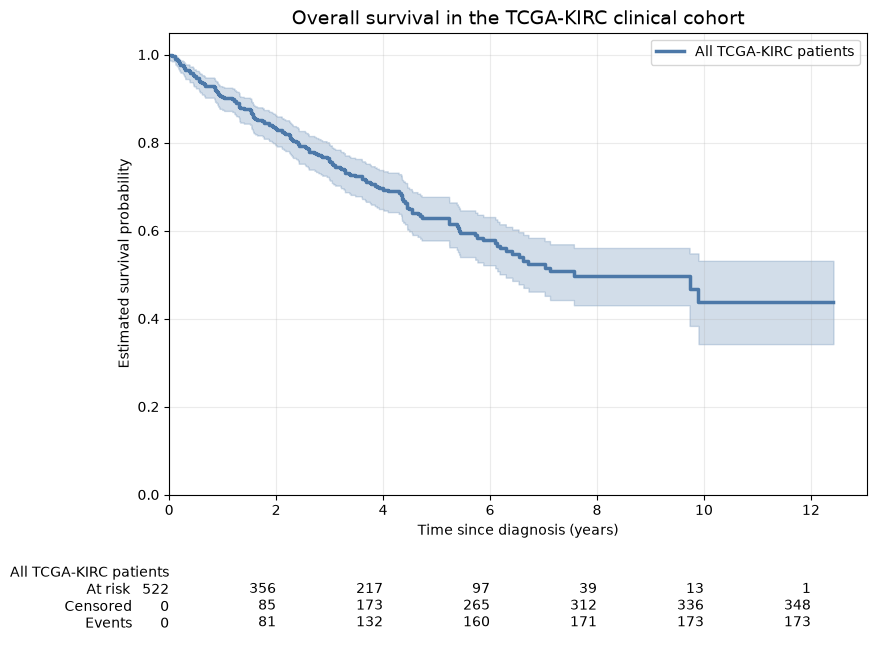

Estimated overall-survival probability:
  1 year(s): 0.904
  3 year(s): 0.759
  5 year(s): 0.629

Figure saved as: figure_02_kaplan_meier_overall_survival.png


In [48]:
# 01-20 Plots overall survival with a Kaplan–Meier curve

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts

# Loads the final clinical survival-analysis cohort.
PROJECT_DIR = Path.cwd().parent
processed_clinical_file = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_survival_analysis = pd.read_csv(processed_clinical_file)

# Fits the Kaplan–Meier survival estimator.
kmf = KaplanMeierFitter()

kmf.fit(
    durations=clinical_survival_analysis["overall_survival_years"],
    event_observed=clinical_survival_analysis["event_observed"],
    label="All TCGA-KIRC patients",
)

# Creates and format the plot.
fig, axis = plt.subplots(figsize=(9, 6))

kmf.plot_survival_function(
    ax=axis,
    ci_show=True,
    color="#4C78A8",
    linewidth=2.5,
)

axis.set_title(
    "Overall survival in the TCGA-KIRC clinical cohort",
    fontsize=14,
)
axis.set_xlabel("Time since diagnosis (years)")
axis.set_ylabel("Estimated survival probability")
axis.set_ylim(0, 1.05)
axis.set_xlim(left=0)
axis.grid(alpha=0.25)

# Adds the number of patients still under observation at selected times.
add_at_risk_counts(kmf, ax=axis)

# Save the figure.
FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_file = FIGURES_DIR / "figure_02_kaplan_meier_overall_survival.png"

plt.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

# Reports estimated survival probabilities at clinically given time points.
survival_at_years = kmf.survival_function_at_times([1, 3, 5])

print("Estimated overall-survival probability:")
for year, probability in survival_at_years.items():
    print(f"  {year} year(s): {probability:.3f}")

print(f"\nFigure saved as: {figure_file.name}")